# 03 Severity modelling

Conditional claim severity, modelled **only on claims with a positive amount** (zero-claim policies never enter the severity target). Fitted on train claims, compared on validation claims; the test split is not read.

In [1]:
import sys, warnings
sys.path.insert(0, "..")            # make the project's src/ package importable from notebooks/
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.utils.config import ROOT, load_config
cfg = load_config()
proc = ROOT / cfg["paths"]["processed_dir"]
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
from src.evaluation.metrics import gamma_deviance, large_claim_analysis, severity_calibration, severity_summary
from src.evaluation.uncertainty import bootstrap_metric_diff
from src.models.severity import ConstantSeverityBaseline, GammaGLM, LightGBMSeverity, RidgeGammaGLM, claims_table
claims = pd.read_parquet(proc / "severity_claims.parquet")
tr = claims_table(pd.read_parquet(proc / "policies_train.parquet"), claims)
va = claims_table(pd.read_parquet(proc / "policies_val.parquet"), claims)
print(f"{len(tr):,} train claims, {len(va):,} validation claims")

15,872 train claims, 5,266 validation claims


In [2]:
models = {"constant_mean": ConstantSeverityBaseline().fit(tr), "gamma_glm": GammaGLM(cfg).fit(tr),
          "ridge_gamma_glm": RidgeGammaGLM(cfg).fit(tr, va), "lightgbm_gamma": LightGBMSeverity(cfg).fit(tr, va)}
rows = [{"model": n, **severity_summary(va["ClaimAmount"], m.predict(va))} for n, m in models.items()]
pd.DataFrame(rows).set_index("model").round(3)

,gamma_deviance,mae,rmse,actual_mean,predicted_mean,actual_to_predicted
model,,,,,,
constant_mean,1.669,2281.086,11579.561,2142.748,2438.255,0.879
gamma_glm,1.726,2240.174,11658.213,2142.748,2314.457,0.926
ridge_gamma_glm,1.664,2187.346,11579.186,2142.748,2309.924,0.928
lightgbm_gamma,1.656,2131.228,11576.816,2142.748,2241.061,0.956


**Reading this:** the unpenalised Gamma GLM is *worse* than the constant mean on validation (it overfits ~16k claims). Differences between the others are small, so uncertainty matters:

In [3]:
y, base = va["ClaimAmount"].to_numpy(), models["constant_mean"].predict(va)
out = []
for n, m in models.items():
    if n == "constant_mean": continue
    r = bootstrap_metric_diff(y, m.predict(va), base, gamma_deviance, n_boot=500, seed=cfg["seed"])
    out.append({"model": n, "gamma_dev_minus_constant": r["diff"], "ci_low": r["ci_low"], "ci_high": r["ci_high"], "reliably_different": r["significant"]})
pd.DataFrame(out).round(4)

,model,gamma_dev_minus_constant,ci_low,ci_high,reliably_different
0,gamma_glm,0.0574,-0.0723,0.1737,False
1,ridge_gamma_glm,-0.0049,-0.0309,0.0245,False
2,lightgbm_gamma,-0.0124,-0.0366,0.0160,False


**Pricing meaning:** if no model is reliably different from a constant, severity relativities between policyholders cannot be trusted; expected-cost differences will come almost entirely from frequency.

## Calibration and large claims

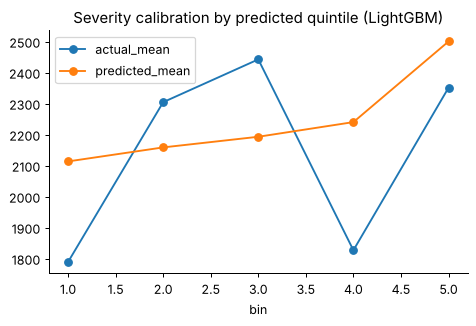

{'threshold': 16338.01, 'n_large': 53, 'share_of_total_cost': 0.34, 'actual_mean_large': 72936.74, 'predicted_mean_large': 3070.56, 'actual_to_predicted_large': 23.75}
Largest train claim: 4,075,401 (mean 2,438); a single claim like this moves the learned severity level.


In [4]:
cal = severity_calibration(y, models["lightgbm_gamma"].predict(va), 5)
ax = cal.plot(x="bin", y=["actual_mean", "predicted_mean"], marker="o", figsize=(6, 3.5), title="Severity calibration by predicted quintile (LightGBM)")
plt.show()
la = large_claim_analysis(y, models["gamma_glm"].predict(va), 0.99)
print({k: round(v, 2) for k, v in la.items()})
print(f"Largest train claim: {tr.ClaimAmount.max():,.0f} (mean {tr.ClaimAmount.mean():,.0f}); a single claim like this moves the learned severity level.")

**Limits:** the top 1% of validation claims account for roughly a third of cost and are under-predicted by a large factor by every model. See `scripts/large_loss_analysis.py` for the (unstable) cap-and-load treatment.